# Football Match Outcome Predictor
Predict home win / draw / away win for international football matches using team strength (Elo rating) and recent form.


**Data:** International football results since 1872 (martj42 dataset on GitHub, no login). If the download fails a small synthetic sample is made.

**Models:** always predict the most common result (baseline), pick the team with higher Elo, Logistic Regression, Gradient Boosting. Train on older matches, test on the newest ones (no shuffling, so no peeking at the future).

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/martj42/international_results/master/results.csv"
try:
    df = pd.read_csv(url)
    print("real data loaded:", df.shape)
except Exception as e:
    print("download failed, making synthetic data instead:", e)
    teams = ["Team" + str(i) for i in range(30)]
    strength = {t: np.random.normal(0, 1) for t in teams}
    rows = []
    for i in range(6000):
        h, a = np.random.choice(teams, 2, replace=False)
        diff = strength[h] - strength[a] + 0.3
        hs = np.random.poisson(max(0.2, 1.4 + 0.4 * diff))
        as_ = np.random.poisson(max(0.2, 1.1 - 0.4 * diff))
        rows.append([pd.Timestamp("1995-01-01") + pd.Timedelta(days=int(i * 1.8)), h, a, hs, as_, "Friendly", False])
    df = pd.DataFrame(rows, columns=["date", "home_team", "away_team", "home_score", "away_score", "tournament", "neutral"])

df["date"] = pd.to_datetime(df["date"])
df = df.dropna(subset=["home_score", "away_score"]).sort_values("date").reset_index(drop=True)
df.tail()

real data loaded: (50099, 9)


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
50094,2026-11-17,Saudi Arabia,Uzbekistan,1,2,Friendly,Al Rayyan,Qatar,True
50095,2026-11-17,Wales,Portugal,2,3,UEFA Nations League,Cardiff,Wales,False
50096,2026-11-17,Denmark,Norway,2,3,UEFA Nations League,Copenhagen,Denmark,False
50097,2026-11-17,Ukraine,Georgia,1,0,UEFA Nations League,Košice,Slovakia,True
50098,2026-11-17,Iraq,Iran,1,1,Basra International Tournament,Basra,Iraq,False


In [3]:
def get_result(row):
    if row.home_score > row.away_score:
        return "home"
    elif row.home_score < row.away_score:
        return "away"
    return "draw"

df["result"] = [get_result(r) for r in df.itertuples()]
print(df["result"].value_counts(normalize=True).round(3))

result
home    0.490
away    0.283
draw    0.227
Name: proportion, dtype: float64


In [4]:
# going through matches in date order, saving the Elo and form BEFORE each match
elo = {}
last_points = {}
rows = []

for r in df.itertuples():
    h = r.home_team
    a = r.away_team
    h_elo = elo.get(h, 1500)
    a_elo = elo.get(a, 1500)
    h_form = np.mean(last_points.get(h, [1.0])[-5:])
    a_form = np.mean(last_points.get(a, [1.0])[-5:])
    h_games = len(last_points.get(h, []))
    a_games = len(last_points.get(a, []))

    rows.append([h_elo, a_elo, h_elo - a_elo, h_form, a_form, int(r.neutral), min(h_games, a_games)])

    home_bonus = 0 if r.neutral else 100
    expected_home = 1 / (1 + 10 ** (-(h_elo + home_bonus - a_elo) / 400))
    if r.result == "home":
        actual_home, h_pts, a_pts = 1, 3, 0
    elif r.result == "away":
        actual_home, h_pts, a_pts = 0, 0, 3
    else:
        actual_home, h_pts, a_pts = 0.5, 1, 1

    goal_diff = abs(r.home_score - r.away_score)
    k = 30 * (1 + 0.25 * min(goal_diff, 4))
    change = k * (actual_home - expected_home)
    elo[h] = h_elo + change
    elo[a] = a_elo - change
    last_points.setdefault(h, []).append(h_pts)
    last_points.setdefault(a, []).append(a_pts)

feat_names = ["home_elo", "away_elo", "elo_diff", "home_form", "away_form", "neutral", "min_games"]
feats = pd.DataFrame(rows, columns=feat_names)
data = pd.concat([df[["date", "home_team", "away_team", "result"]], feats], axis=1)
data = data[(data["date"] >= "2000-01-01") & (data["min_games"] >= 5)]
print(data.shape)
print("top 10 teams by final Elo:")
print(pd.Series(elo).sort_values(ascending=False).head(10).round(0))

(25750, 11)
top 10 teams by final Elo:
Spain          2249.0
Argentina      2183.0
England        2160.0
France         2124.0
Portugal       2064.0
Brazil         2064.0
Belgium        2047.0
Colombia       2041.0
Germany        2018.0
Switzerland    2016.0
dtype: float64


In [5]:
cut_date = data["date"].quantile(0.85)
train = data[data["date"] < cut_date]
test = data[data["date"] >= cut_date]
print("train:", len(train), "test:", len(test))
print("test starts:", test["date"].min().date())

X_cols = ["elo_diff", "home_form", "away_form", "neutral", "home_elo", "away_elo"]
X_train, y_train = train[X_cols], train["result"]
X_test, y_test = test[X_cols], test["result"]

train: 21886 test: 3864
test starts: 2023-06-25


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report

most_common = y_train.mode()[0]
print("Baseline (always", most_common + "):", round(accuracy_score(y_test, [most_common] * len(y_test)), 4))

elo_pred = np.where(test["elo_diff"] + 100 * (1 - test["neutral"]) > 0, "home", "away")
print("Higher Elo wins accuracy:", round(accuracy_score(y_test, elo_pred), 4))

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)
print("Logistic Regression accuracy:", round(accuracy_score(y_test, lr_pred), 4), " log loss:", round(log_loss(y_test, lr_prob, labels=lr.classes_), 4))

gb = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=4, random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
gb_prob = gb.predict_proba(X_test)
print("Gradient Boosting accuracy:", round(accuracy_score(y_test, gb_pred), 4), " log loss:", round(log_loss(y_test, gb_prob, labels=gb.classes_), 4))

base_prob = np.tile(y_train.value_counts(normalize=True).reindex(lr.classes_).values, (len(y_test), 1))
print("Baseline log loss:", round(log_loss(y_test, base_prob, labels=lr.classes_), 4))

Baseline (always home): 0.4764
Higher Elo wins accuracy: 0.6066
Logistic Regression accuracy: 0.6048  log loss: 0.8634
Gradient Boosting accuracy: 0.6048  log loss: 0.8656
Baseline log loss: 1.051


In [7]:
print(classification_report(y_test, lr_pred))
print(pd.DataFrame(confusion_matrix(y_test, lr_pred, labels=["home", "draw", "away"]), index=["real home", "real draw", "real away"], columns=["pred home", "pred draw", "pred away"]))

              precision    recall  f1-score   support

        away       0.57      0.64      0.60      1139
        draw       0.12      0.00      0.00       884
        home       0.63      0.87      0.73      1841

    accuracy                           0.60      3864
   macro avg       0.44      0.50      0.44      3864
weighted avg       0.49      0.60      0.52      3864

           pred home  pred draw  pred away
real home       1606          3        232
real draw        557          1        326
real away        405          4        730


            matches  predicted  actual
bucket                                
(0.0, 0.2]    671.0      0.109   0.100
(0.2, 0.4]    810.0      0.304   0.279
(0.4, 0.6]    873.0      0.502   0.488
(0.6, 0.8]    962.0      0.700   0.662
(0.8, 1.0]    548.0      0.869   0.885


/tmp/ipykernel_1106/222355732.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  check = test.groupby("bucket", observed=True).apply(lambda g: pd.Series({"matches": len(g), "predicted": g["home_win_prob"].mean(), "actual": (g["result"] == "home").mean()}))


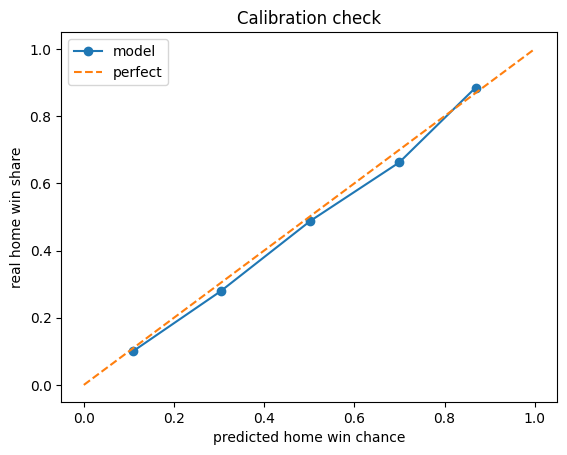

In [8]:
test = test.copy()
test["home_win_prob"] = lr_prob[:, list(lr.classes_).index("home")]
test["bucket"] = pd.cut(test["home_win_prob"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
check = test.groupby("bucket", observed=True).apply(lambda g: pd.Series({"matches": len(g), "predicted": g["home_win_prob"].mean(), "actual": (g["result"] == "home").mean()}))
print(check.round(3))

plt.plot(check["predicted"], check["actual"], marker="o", label="model")
plt.plot([0, 1], [0, 1], linestyle="--", label="perfect")
plt.xlabel("predicted home win chance")
plt.ylabel("real home win share")
plt.title("Calibration check")
plt.legend()
plt.show()

In [9]:
latest = data.drop_duplicates("home_team", keep="last")
print("Example: predicting a match with two strong teams on neutral ground")
top = pd.Series(elo).sort_values(ascending=False).head(2)
a_name, b_name = top.index[0], top.index[1]
example = pd.DataFrame([[top.iloc[0] - top.iloc[1], 2.0, 2.0, 1, top.iloc[0], top.iloc[1]]], columns=X_cols)
print(a_name, "vs", b_name)
print(dict(zip(lr.classes_, lr.predict_proba(example)[0].round(3))))

Example: predicting a match with two strong teams on neutral ground
Spain vs Argentina
{'away': np.float64(0.296), 'draw': np.float64(0.331), 'home': np.float64(0.374)}


In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)